# Imports & Device Verification

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from pycocotools.coco import COCO
from tqdm.notebook import tqdm


# Set seed
torch.manual_seed(42)
np.random.seed(42)

# Verify Tesla P100
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Active Device: cuda
GPU Model: Tesla T4


# Dataset Class & Preprocessing Pipeline

In [2]:
def remove_limb_darkening(image_gray, kernel_size=151):
    """
    Equalizes solar background brightness by dividing by a large median filter.
    """
    bg = cv2.medianBlur(image_gray, kernel_size)
    bg = np.maximum(bg, 1)
    corrected = (image_gray.astype(np.float32) / bg.astype(np.float32)) * 128.0
    return np.clip(corrected, 0, 255).astype(np.uint8)


class SolarFilamentDataset(Dataset):
    """
    Dataset for MAGFiLO Solar Filament Challenge.
    Parses COCO JSON, applies limb darkening correction, and outputs Mask R-CNN targets.
    """
    def __init__(self, image_dir: str, json_path: str):
        self.image_dir = image_dir
        self.coco = COCO(json_path)
        self.img_ids = list(self.coco.imgs.keys())

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_info = self.coco.imgs[img_id]
        
        img_path = os.path.join(self.image_dir, img_info['file_name'])
        image_gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if image_gray is None:
            raise FileNotFoundError(f"Image not found at {img_path}")
            
        # Apply Limb Darkening Correction
        image_corr = remove_limb_darkening(image_gray)
        
        # CPU-side Normalization
        image_rgb = np.stack([image_corr] * 3, axis=-1).astype(np.float32) / 255.0
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        image_norm = (image_rgb - mean) / std
        
        image_tensor = torch.from_numpy(image_norm).permute(2, 0, 1).float()
        
        ann_ids = self.coco.getAnnIds(imgIds=[img_id])
        anns = self.coco.loadAnns(ann_ids)
        
        masks = []
        boxes = []
        labels = []
        
        for ann in anns:
            mask = self.coco.annToMask(ann)
            if mask.sum() == 0:
                continue
                
            x, y, w, h = ann['bbox']
            x1, y1 = max(0, x), max(0, y)
            x2, y2 = min(2048, x + w), min(2048, y + h)
            
            if x2 <= x1 or y2 <= y1:
                continue
                
            masks.append(mask)
            boxes.append([x1, y1, x2, y2])
            labels.append(1)  # Binary class: 1 = Filament
            
        if len(masks) > 0:
            target = {
                "boxes": torch.as_tensor(boxes, dtype=torch.float32),
                "labels": torch.as_tensor(labels, dtype=torch.int64),
                "masks": torch.as_tensor(np.stack(masks, axis=0), dtype=torch.uint8),
                "image_id": torch.tensor([idx])
            }
        else:
            target = {
                "boxes": torch.zeros((0, 4), dtype=torch.float32),
                "labels": torch.zeros((0,), dtype=torch.int64),
                "masks": torch.zeros((0, 2048, 2048), dtype=torch.uint8),
                "image_id": torch.tensor([idx])
            }

        return image_tensor, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Model Architecture & Dice Metric Helper

In [3]:
def get_maskrcnn_model(num_classes=2):
    """
    Mask R-CNN with ResNet-50 FPN backbone.
    Sets zero mean/std to skip internal CUDA normalization kernels.
    """
    model = torchvision.models.detection.maskrcnn_resnet50_fpn(
        weights="DEFAULT",
        image_mean=[0.0, 0.0, 0.0],
        image_std=[1.0, 1.0, 1.0]
    )
    
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, hidden_layer, num_classes)
    
    return model


def compute_dice_score(pred_masks, gt_masks, score_thresh=0.5):
    """
    Computes bipartite-matched mean Dice Score between predicted and ground-truth masks.
    """
    if len(pred_masks) == 0 and len(gt_masks) == 0:
        return 1.0
    if len(pred_masks) == 0 or len(gt_masks) == 0:
        return 0.0
        
    pred_binary = (pred_masks > score_thresh).astype(np.float32)
    gt_binary = (gt_masks > 0).astype(np.float32)
    
    pred_flat = pred_binary.reshape(pred_binary.shape[0], -1)
    gt_flat = gt_binary.reshape(gt_binary.shape[0], -1)
    
    intersection = np.dot(pred_flat, gt_flat.T)
    pred_sums = pred_flat.sum(axis=1, keepdims=True)
    gt_sums = gt_flat.sum(axis=1, keepdims=True)
    
    dice_matrix = (2.0 * intersection) / (pred_sums + gt_sums.T + 1e-6)
    
    matched_dice = []
    while dice_matrix.size > 0 and dice_matrix.max() > 0:
        max_idx = np.unravel_index(np.argmax(dice_matrix), dice_matrix.shape)
        matched_dice.append(dice_matrix[max_idx])
        dice_matrix = np.delete(dice_matrix, max_idx[0], axis=0)
        dice_matrix = np.delete(dice_matrix, max_idx[1], axis=1)
        
    return np.mean(matched_dice) if len(matched_dice) > 0 else 0.0

# Data Loaders & Model Initialization

In [4]:
BASE_DIR = "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "train/train_images")
TRAIN_JSON_PATH = os.path.join(BASE_DIR, "train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")

full_dataset = SolarFilamentDataset(image_dir=TRAIN_IMG_DIR, json_path=TRAIN_JSON_PATH)

# Train/Val Split
val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=2, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=2, collate_fn=collate_fn)

print(f"Dataset Loaded: Train = {len(train_dataset)} | Val = {len(val_dataset)}")

model = get_maskrcnn_model(num_classes=2).to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": []
}

loading annotations into memory...
Done (t=0.95s)
creating index...
index created!
Dataset Loaded: Train = 924 | Val = 230
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 175MB/s]


# Tesla P100 Execution Loop

In [5]:
NUM_EPOCHS = 20

for epoch in range(NUM_EPOCHS):
    # --- A. TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0
    train_dice_scores = []
    
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, targets in train_pbar:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        # Forward pass & Loss calculation
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        
        running_train_loss += losses.item()
        
        # Calculate Training Dice on current batch in eval mode
        with torch.no_grad():
            model.eval()
            batch_preds = model(images)
            for i in range(len(images)):
                p_masks = batch_preds[i]['masks'].squeeze(1).detach().cpu().numpy()
                g_masks = targets[i]['masks'].detach().cpu().numpy()
                train_dice_scores.append(compute_dice_score(p_masks, g_masks))
            model.train()
            
        train_pbar.set_postfix({"loss": f"{losses.item():.4f}"})

    avg_train_loss = running_train_loss / len(train_loader)
    avg_train_dice = np.mean(train_dice_scores)
    lr_scheduler.step()

    # --- B. VALIDATION PHASE ---
    running_val_loss = 0.0
    val_dice_scores = []
    
    # 1. Compute Validation Loss (requires model.train() for loss output)
    model.train()
    with torch.no_grad():
        for images, targets in val_loader:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            
            val_loss_dict = model(images, targets)
            val_losses = sum(loss for loss in val_loss_dict.values())
            running_val_loss += val_losses.item()

    # 2. Compute Validation Predictions & Dice Score
    model.eval()
    val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val Dice]")
    with torch.no_grad():
        for images, targets in val_pbar:
            images = [img.to(device) for img in images]
            predictions = model(images)
            
            p_masks = predictions[0]['masks'].squeeze(1).detach().cpu().numpy()
            g_masks = targets[0]['masks'].detach().cpu().numpy()
            
            dice = compute_dice_score(p_masks, g_masks)
            val_dice_scores.append(dice)
            val_pbar.set_postfix({"dice": f"{dice:.4f}"})

    avg_val_loss = running_val_loss / len(val_loader)
    avg_val_dice = np.mean(val_dice_scores)

    # Store Metrics in History Dictionary
    if "train_dice" not in history:
        history["train_dice"] = []
        
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_dice"].append(avg_train_dice)
    history["val_dice"].append(avg_val_dice)

    # Printable Summary Table for Epoch
    print("\n" + "=" * 65)
    print(f"EPOCH [{epoch+1}/{NUM_EPOCHS}] PERFORMANCE METRICS SUMMARY")
    print("=" * 65)
    print(f"Train Loss:       {avg_train_loss:.4f}  |  Val Loss:       {avg_val_loss:.4f}")
    print(f"Train Dice Score: {avg_train_dice:.4f}  |  Val Dice Score: {avg_val_dice:.4f}")
    print("=" * 65 + "\n")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save Model Checkpoint
MODEL_SAVE_PATH = "maskrcnn_magfilo2026.pth"
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

Epoch 1/20 [Train]:   0%|          | 0/462 [00:00<?, ?it/s]

Epoch 1/20 [Val Dice]:   0%|          | 0/230 [00:00<?, ?it/s]


EPOCH [1/20] PERFORMANCE METRICS SUMMARY
Train Loss:       0.9322  |  Val Loss:       0.9226
Train Dice Score: 0.6936  |  Val Dice Score: 0.7173



Epoch 2/20 [Train]:   0%|          | 0/462 [00:00<?, ?it/s]

Epoch 2/20 [Val Dice]:   0%|          | 0/230 [00:00<?, ?it/s]


EPOCH [2/20] PERFORMANCE METRICS SUMMARY
Train Loss:       0.8131  |  Val Loss:       0.8442
Train Dice Score: 0.7271  |  Val Dice Score: 0.7173



... (50 outputs left out)


EPOCH [19/20] PERFORMANCE METRICS SUMMARY
Train Loss:       0.6240  |  Val Loss:       0.8160
Train Dice Score: 0.7574  |  Val Dice Score: 0.7283



Epoch 20/20 [Train]:   0%|          | 0/462 [00:00<?, ?it/s]

Epoch 20/20 [Val Dice]:   0%|          | 0/230 [00:00<?, ?it/s]


EPOCH [20/20] PERFORMANCE METRICS SUMMARY
Train Loss:       0.6249  |  Val Loss:       0.8108
Train Dice Score: 0.7574  |  Val Dice Score: 0.7283

Model saved to maskrcnn_magfilo2026.pth


# Plot Metric Charts

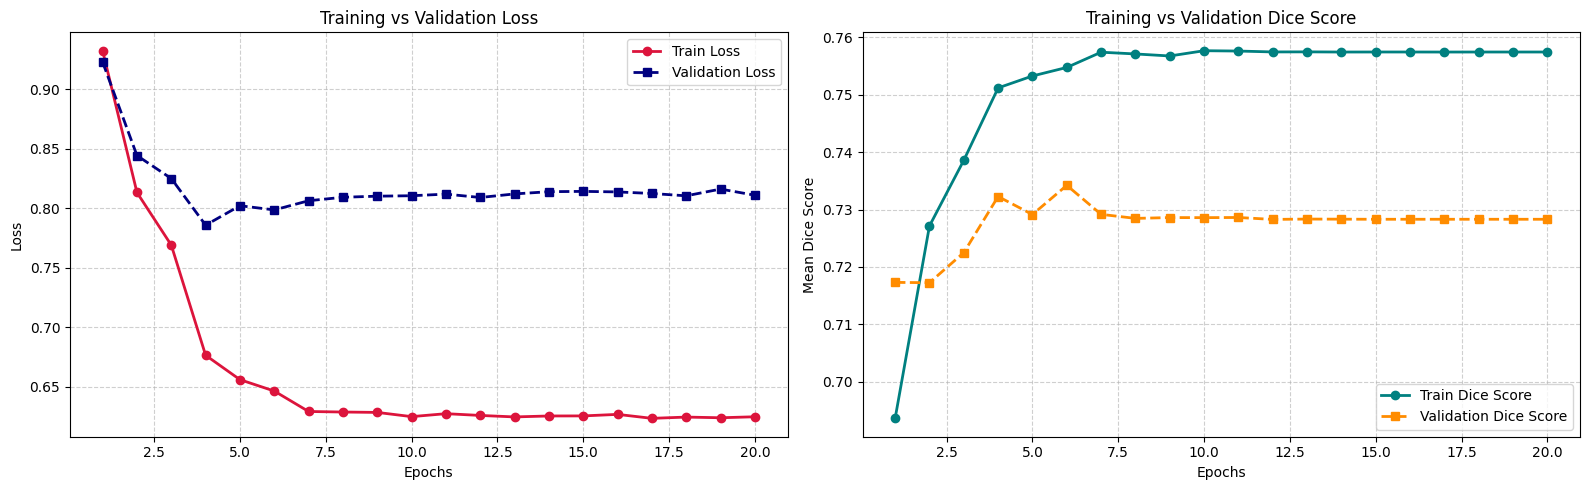

In [6]:
epochs_range = range(1, NUM_EPOCHS + 1)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Train vs Validation Loss
ax[0].plot(epochs_range, history["train_loss"], 'o-', color='crimson', linewidth=2, label='Train Loss')
ax[0].plot(epochs_range, history["val_loss"], 's--', color='navy', linewidth=2, label='Validation Loss')
ax[0].set_title("Training vs Validation Loss")
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Loss")
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend()

# Plot 2: Train vs Validation Dice Score
ax[1].plot(epochs_range, history["train_dice"], 'o-', color='teal', linewidth=2, label='Train Dice Score')
ax[1].plot(epochs_range, history["val_dice"], 's--', color='darkorange', linewidth=2, label='Validation Dice Score')
ax[1].set_title("Training vs Validation Dice Score")
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Mean Dice Score")
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend()

plt.tight_layout()
plt.show()